# Tekstų klasifikavimas: šeši Fakeddit įrašų tipai pagal antraštę

Kiekviena antraštė priskiriama vienai iš šešių Fakeddit klasių: tikras, satyra / parodija, klaidingas ryšys, apsimetėlio turinys, redaguotas turinys ar klaidinantis turinys. Naudojamas tik antraštės tekstas.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from pathlib import Path
from sklearn.pipeline import make_pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

DATA = Path("../data/multimodal_only_samples-20261006T085257Z-1-001/multimodal_only_samples")
FIG = Path("../report/figures"); FIG.mkdir(parents=True, exist_ok=True)  # grafikus iskart saugom ataskaitai
MODEL_PATH = Path("../models/svm_6way.joblib")
CLASSES = ["true", "satire/parody", "false connection", "imposter content", "manipulated content", "misleading content"]  # 6_way_label 0-5; pavadinimai pagal straipsnio 7 lentele (kuris subreddit kuriai klasei)

## 1. Duomenų įkėlimas
Naudojamas oficialus Fakeddit padalijimas. `subreddit` įkeliamas tik rezultatams grupuoti, modelis jo nemato.

In [2]:
COLS = ["clean_title", "subreddit", "6_way_label"]
load = lambda name: pd.read_csv(DATA / f"multimodal_{name}.tsv", sep="\t", usecols=COLS)
train, val, test = load("train"), load("validate"), load("test_public")
for df in (train, val, test):
    df["type"] = pd.Categorical(df["6_way_label"].map(dict(enumerate(CLASSES))), categories=CLASSES)  # skaiciu paverciam pavadinimu, kad lenteles butu skaitomos
train.shape, val.shape, test.shape

((564000, 4), (59342, 4), (59319, 4))

## 2. Duomenų apžvalga

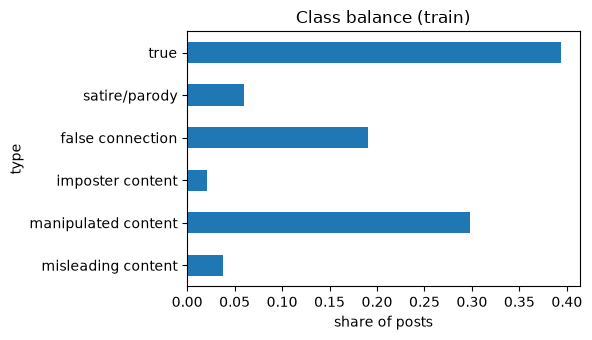

type
true                   0.394
satire/parody          0.059
false connection       0.190
imposter content       0.021
manipulated content    0.298
misleading content     0.038
Name: proportion, dtype: float64

In [3]:
share = train["type"].value_counts(normalize=True).reindex(CLASSES)
ax = share.plot.barh(figsize=(6, 3.5), title="Class balance (train)")
ax.invert_yaxis(); ax.set_xlabel("share of posts")
plt.tight_layout(); plt.savefig(FIG / "txt_class_balance.png", dpi=120); plt.show()
share.round(3)

In [4]:
sub = train.groupby("subreddit").agg(type=("type", "first"), labels=("6_way_label", "nunique"), posts=("type", "size"))  # labels = kiek skirtingu klasiu turi subreddit
print("Subreddits with more than one label:", (sub["labels"] > 1).sum())
sub.drop(columns="labels").sort_values(["type", "posts"], ascending=[True, False])

Subreddits with more than one label: 0


,type,posts
subreddit,,
mildlyinteresting,true,86237
photoshopbattles,true,55198
nottheonion,true,31977
upliftingnews,true,23960
neutralnews,true,7512
usnews,true,5941
usanews,true,5875
pic,true,5381
fakealbumcovers,satire/parody,21725


Kiekvienas subreddit turi vieną žymę, o kai kurias klases sudaro vienas subreddit (redaguotas turinys yra tik `psbattle_artwork`), todėl modelis mokosi, kaip kiekviena subreddit grupė rašo antraštes. Dėl tos pačios priežasties ištisų subreddit testui atidėti negalima.

In [5]:
train["title_words"] = train["clean_title"].str.split().str.len()
train.groupby("type", observed=True)["title_words"].describe().round(1)  # ar klases skiriasi antrasciu ilgiu

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
true,222081.0,9.5,5.6,1.0,6.0,9.0,12.0,66.0
satire/parody,33481.0,7.6,5.5,1.0,4.0,6.0,10.0,56.0
false connection,107221.0,7.2,4.7,1.0,4.0,6.0,9.0,58.0
imposter content,11784.0,14.6,6.4,1.0,10.0,14.0,18.0,61.0
manipulated content,167857.0,4.0,3.8,1.0,2.0,3.0,5.0,553.0
misleading content,21576.0,11.2,6.2,1.0,7.0,10.0,14.0,54.0


## 3. Požymiai ir modelis
Antraštė paverčiama TF-IDF vektoriais iš 200 000 žodžių ir žodžių porų bei 2-5 raidžių sekų. Dažni žodžiai kaip „my“, „this“, „i“ paliekami, nes jie yra dalis bendruomenės stiliaus, o raidžių sekos pagauna rašybos variantus ir žodžių dalis. Klasifikatorius yra `LinearSVC` (C=0.3) su klasių svoriais, lygiais kvadratinei šakniai iš „balanced“: su pilnais svoriais retos klasės spėjamos per dažnai, be jų dominuoja didelės.

| Modelis (validacija) | Macro F1 | Accuracy |
|---|---|---|
| Tik žodžiai be dažnų žodžių, logistinė regresija | 0,522 | 63,0 % |
| Dažni žodžiai palikti | 0,563 | 66,4 % |
| 200k žodžių, C=10 | 0,600 | 70,8 % |
| Žodžiai ir raidžių sekos, Complement Naive Bayes | 0,532 | 69,3 % |
| Žodžiai ir raidžių sekos, logistinė regresija | 0,624 | 72,7 % |
| Žodžiai ir raidžių sekos, tiesinis SVM | 0,641 | 75,1 % |
| Tas pats, perpus mažesni svoriai | 0,644 | 76,2 % |

In [6]:
if MODEL_PATH.exists():
    model = joblib.load(MODEL_PATH)  # jau ismokytas, nemokom is naujo
else:
    y = train["6_way_label"]
    half = dict(enumerate((len(y) / (6 * np.bincount(y))) ** 0.5))  # saknis is 'balanced' svoriu: retos klases svarbesnes, bet ne 19 kartu
    model = make_pipeline(
        FeatureUnion([
            ("words", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=200_000, sublinear_tf=True, dtype=np.float32)),  # stop zodziu neismetam, jie rodo rasymo stiliu
            ("chars", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, max_features=200_000, sublinear_tf=True, dtype=np.float32)),  # zodziu dalys pagauna rasybos variantus; float32 perpus maziau atminties
        ]),
        LinearSVC(C=0.3, class_weight=half),  # C ir svoriai parinkti pagal validacijos macro F1
    )
    model.fit(train["clean_title"], y)
    joblib.dump(model, MODEL_PATH)
words, chars = (t for _, t in model[0].transformer_list)
print("Word features:", len(words.vocabulary_), " character features:", len(chars.vocabulary_))

Word features: 200000  character features: 153036


## 4. Įvertinimas
Pagrindinis įvertis yra macro F1, nes jis vienodai vidurkina visas šešias klases. Dažniausios klasės modelis visada atsako „tikras“.

In [7]:
rows = {}
for name, df in [("validation", val), ("test", test)]:
    pred = model.predict(df["clean_title"])
    y = df["6_way_label"]
    rows[(name, "baseline")] = {"accuracy": (y == 0).mean(), "macro F1": f1_score(y, np.zeros_like(y), average="macro")}
    rows[(name, "model")] = {"accuracy": accuracy_score(y, pred), "macro F1": f1_score(y, pred, average="macro")}
test["pred"] = pred  # paskutinis ciklo zingsnis yra testas
pd.DataFrame(rows).T.round(4)

accuracy  macro F1
validation baseline    0.3930    0.0940
           model       0.7623    0.6445
test       baseline    0.3963    0.0946
           model       0.7650    0.6502

In [8]:
print(classification_report(test["6_way_label"], test["pred"], target_names=CLASSES, digits=4))  # precision: kiek spejimu teisingi; recall: kiek tos klases irasu rasta

                     precision    recall  f1-score   support

               true     0.7998    0.8492    0.8238     23507
      satire/parody     0.5980    0.4670    0.5244      3514
   false connection     0.7151    0.6095    0.6581     11297
   imposter content     0.4374    0.3056    0.3598      1224
manipulated content     0.7867    0.8535    0.8187     17472
 misleading content     0.7378    0.6959    0.7162      2305

           accuracy                         0.7650     59319
          macro avg     0.6791    0.6301    0.6502     59319
       weighted avg     0.7580    0.7650    0.7592     59319



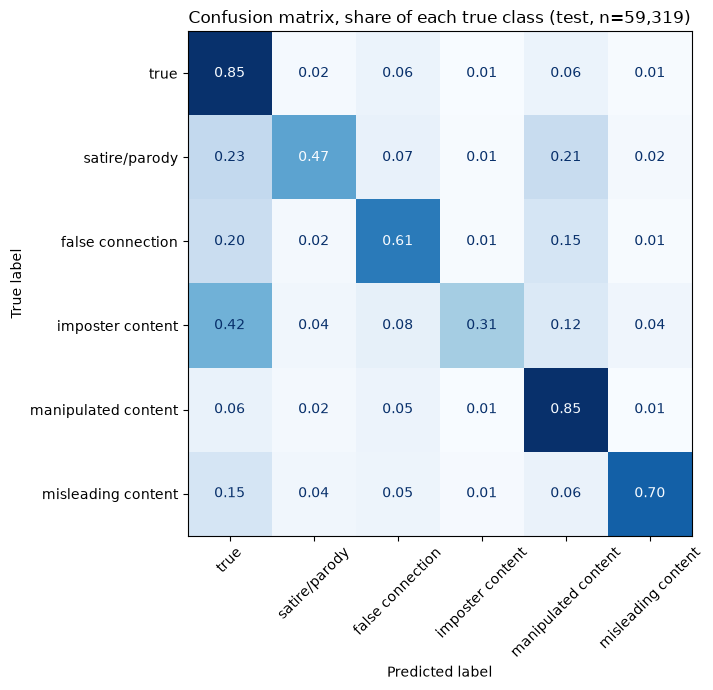

In [9]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(test["6_way_label"], test["pred"], display_labels=CLASSES, normalize="true",  # eilutes procentais, kitaip mazos klases nesimatytu
                                        values_format=".2f", cmap="Blues", colorbar=False, xticks_rotation=45, ax=ax)
ax.set_title(f"Confusion matrix, share of each true class (test, n={len(test):,})")
plt.tight_layout(); plt.savefig(FIG / "txt_confusion.png", dpi=120); plt.show()

## 5. Rezultatai pagal subreddit
Kiekviena klasė yra subreddit grupė, todėl matyti, kurias bendruomenes modelis atpažįsta, o kurias painioja.

In [10]:
test["correct"] = test["pred"] == test["6_way_label"]
wrong_as = test[~test["correct"]].groupby("subreddit")["pred"].agg(lambda p: CLASSES[p.mode()[0]])  # i kuria klase dazniausiai suklysta
by_sub = test.groupby("subreddit").agg(type=("type", "first"), posts=("correct", "size"), recall=("correct", "mean"))
by_sub["most often wrong as"] = wrong_as
by_sub.sort_values(["type", "recall"]).round(3)

,type,posts,recall,most often wrong as
subreddit,,,,
pic,true,619,0.643,manipulated content
photoshopbattles,true,5850,0.755,manipulated content
mildlyinteresting,true,9037,0.875,false connection
neutralnews,true,791,0.877,satire/parody
usnews,true,613,0.891,satire/parody
nottheonion,true,3377,0.894,satire/parody
usanews,true,631,0.899,satire/parody
upliftingnews,true,2589,0.934,satire/parody
satire,satire/parody,402,0.234,true


## 6. Svarbiausi žodžiai kiekvienai klasei
Žodžiai su didžiausiu svoriu labiausiai traukia antraštę link tos klasės. Raidžių sekos neparodytos, nes jas sunku skaityti.

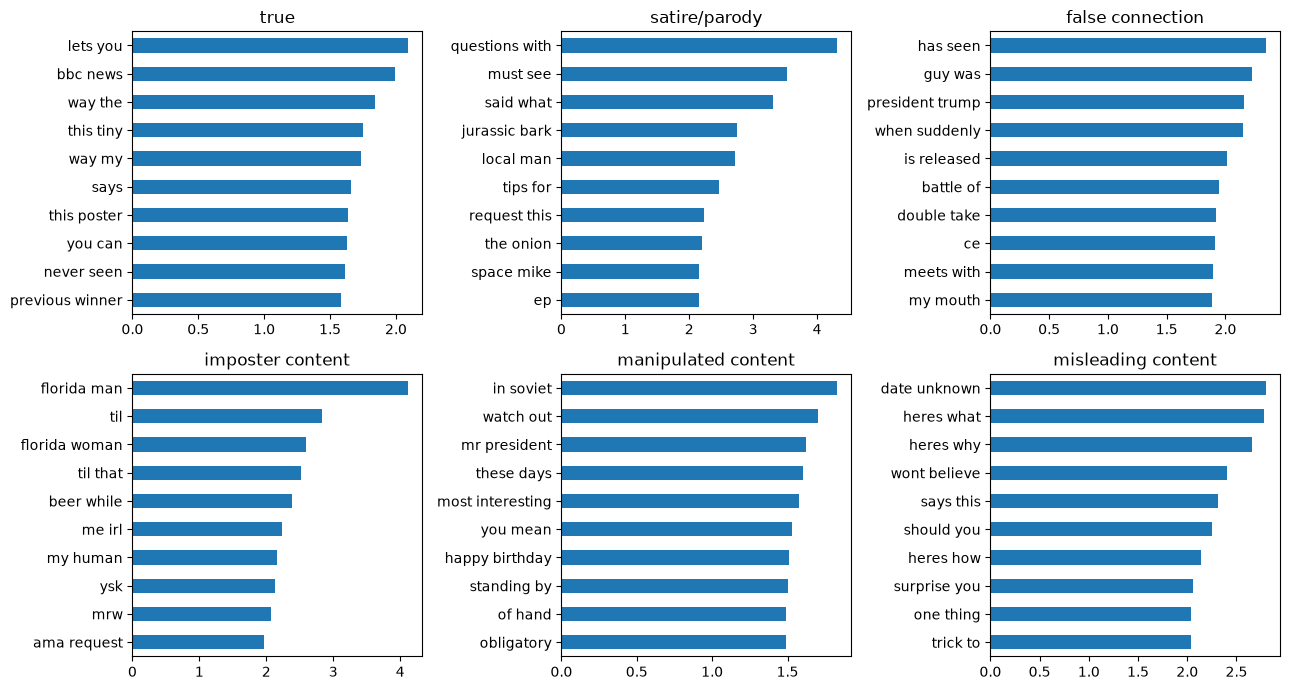

,true,satire/parody,false connection,imposter content,manipulated content,misleading content
0,lets you,questions with,has seen,florida man,in soviet,date unknown
1,bbc news,must see,guy was,til,watch out,heres what
2,way the,said what,president trump,florida woman,mr president,heres why
3,this tiny,jurassic bark,when suddenly,til that,these days,wont believe
4,way my,local man,is released,beer while,most interesting,says this
5,says,tips for,battle of,me irl,you mean,should you
6,this poster,request this,double take,my human,happy birthday,heres how
7,you can,the onion,ce,ysk,standing by,surprise you
8,never seen,space mike,meets with,mrw,of hand,one thing
9,previous winner,ep,my mouth,ama request,obligatory,trick to


In [11]:
names = words.get_feature_names_out()
coef = pd.DataFrame(model[-1].coef_[:, :len(names)].T, index=names, columns=CLASSES)  # pirmi stulpeliai yra zodziai, po ju eina raidziu gabalai
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.ravel(), CLASSES):
    coef[c].nlargest(10).sort_values().plot.barh(ax=ax, title=c)
plt.tight_layout(); plt.savefig(FIG / "txt_top_words.png", dpi=120); plt.show()
pd.DataFrame({c: coef[c].nlargest(10).index for c in CLASSES})

## 7. Pavyzdžiai
Atsitiktinės testo antraštės su spėta ir tikra klase.

In [12]:
pd.set_option("display.max_colwidth", 80)
sample = test.sample(15, random_state=42)  # atsitiktiniai, kad matytume ir teisingus, ir klaidingus
pd.DataFrame({"title": sample["clean_title"], "subreddit": sample["subreddit"], "true class": sample["type"],
              "predicted": sample["pred"].map(dict(enumerate(CLASSES)))})

,title,subreddit,true class,predicted
22783,the pick,psbattle_artwork,manipulated content,manipulated content
53435,me jumping in a big leaf pile,photoshopbattles,true,true
36562,this lemon that has a face,mildlyinteresting,true,true
2867,amazon is selling cck rings now,misleadingthumbnails,false connection,true
46547,hot farmgirl mocking a cow,photoshopbattles,true,true
1866,saddam hussein is executed,fakehistoryporn,false connection,false connection
54263,the one yellow kernel in my white corn,mildlyinteresting,true,true
44313,no more mr nice guy,psbattle_artwork,manipulated content,manipulated content
45323,bill oreilly says same sex marriage foes are just a bunch of bible thumpers,nottheonion,true,true
37369,beer me,psbattle_artwork,manipulated content,false connection
